<a href="https://colab.research.google.com/github/aishwaryaaramanathan/DL_Lab_241501011/blob/main/dl_exp_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [2]:
# Load CIFAR-10 dataset
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])

trainset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform
)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=128, shuffle=True
)


100%|██████████| 170M/170M [1:05:34<00:00, 43.3kB/s]


In [3]:
# Define MLP
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.net(x)

In [4]:
# Training function
def train(optimizer, model, epochs=5):
    loss_fn = nn.CrossEntropyLoss()
    losses, accuracies = [], []

    model.to(device)

    for epoch in range(epochs):
        total_loss, correct, total = 0, 0, 0
        model.train()

        for imgs, labels in trainloader:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        losses.append(total_loss / len(trainloader))
        accuracies.append(100 * correct / total)

        print(f"Epoch {epoch+1}: Loss={losses[-1]:.4f}, "
              f"Accuracy={accuracies[-1]:.2f}%")

    return losses, accuracies

In [5]:
# Train using SGD with momentum
torch.manual_seed(42)
model_sgd = MLP().to(device)
sgd = optim.SGD(model_sgd.parameters(), lr=0.01, momentum=0.9)
loss_sgd, acc_sgd = train(sgd, model_sgd)

Epoch 1: Loss=1.7003, Accuracy=40.16%
Epoch 2: Loss=1.4831, Accuracy=48.12%
Epoch 3: Loss=1.3817, Accuracy=51.76%
Epoch 4: Loss=1.3160, Accuracy=54.11%
Epoch 5: Loss=1.2580, Accuracy=56.30%


In [6]:
# Train using Adam
torch.manual_seed(42)
model_adam = MLP().to(device)
adam = optim.Adam(model_adam.parameters(), lr=0.001)
loss_adam, acc_adam = train(adam, model_adam)

Epoch 1: Loss=1.6355, Accuracy=42.60%
Epoch 2: Loss=1.4336, Accuracy=49.81%
Epoch 3: Loss=1.3485, Accuracy=52.96%
Epoch 4: Loss=1.2822, Accuracy=55.18%
Epoch 5: Loss=1.2222, Accuracy=57.65%


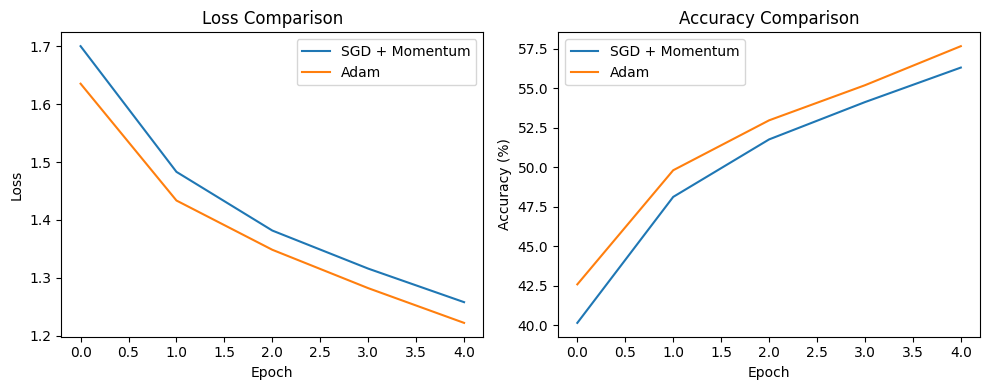

In [7]:
# Compare loss and accuracy
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(loss_sgd, label='SGD + Momentum')
plt.plot(loss_adam, label='Adam')
plt.title('Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(acc_sgd, label='SGD + Momentum')
plt.plot(acc_adam, label='Adam')
plt.title('Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()